![Universidad Iberoamericana del Ecuador](https://raw.githubusercontent.com/andresrubiop/ml-unibe-estudiantes/main/utils/logo-unibe-color.png)

<div style="background:#004890;color:#FFFFFF;padding:14px 18px;border-radius:10px;margin:6px 0 12px 0;border-bottom:4px solid #FCC000"><div style="font-size:12px;letter-spacing:.08em;text-transform:uppercase;opacity:.9">Machine Learning · Trabajo final · Producto final · 30 % de la nota</div><div style="font-size:22px;font-weight:700;margin-top:4px">Trabajo final · Proyecto integrador de machine learning sobre un caso de Big Data</div><div style="font-size:12px;opacity:.9;margin-top:4px">Posgrado · Maestría en Big Data y Ciencia de Datos · UNIB.E</div></div>

| | |
|---|---|
| **Qué entregas** | **Solo este notebook ejecutado** (`.ipynb`), renombrado `TF_Apellido_Nombre.ipynb`, en el aula virtual. **El notebook es tu informe**: no hay documento ni presentación aparte. |
| **Fecha** | **Jueves 19 de noviembre de 2026** |
| **Trabajo** | Individual |
| **Peso** | 3 puntos (30 % de la nota final) · rúbrica al final de este notebook y en el aula |
| **Uso de IA** | **Permitido sin límite**: Claude Code, Codex, ChatGPT, Gemini en Colab, Copilot u otra herramienta, siempre que lo **declares** en la sección 12. |
| **Teoría** | Todo el módulo: M1 (supervisado y evaluación) y M2 (no supervisado, conocimiento y escala) |

**Qué vas a hacer.** Resolver de principio a fin un caso de Big Data: plantear el problema, preparar los datos sin fugas, comparar al menos tres modelos con validación cruzada, aplicar una técnica no supervisada o de extracción del conocimiento, evaluar una sola vez en la prueba y explicar el resultado a quien decide.

**Cómo está armada esta plantilla.** Ya trae un **caso de ejemplo que funciona** (ingresos de adultos del censo de EE. UU., 48 842 personas, de OpenML) para que veas el flujo completo. **Cámbialo por tu caso** en la sección 2: el resto de las celdas está escrito para adaptarse a cualquier tabla con una columna objetivo. Si aún no tienes caso, la lista de la sección 2 trae conjuntos públicos.

**Secciones:** 0 · cómo trabajar → 1 · ficha del proyecto → 2 · datos → 3 · exploración → 4 · partición sin fugas y baseline → 5 · preparación → 6 · tres modelos con validación cruzada → 7 · técnica no supervisada o de conocimiento → 8 · evaluación final → 9 · interpretación → 10 · conclusiones para quien decide → 11 · reproducibilidad → 12 · declaración de IA → lista de control.

## 0 · Cómo trabajar este notebook

1. **Guarda tu copia.** En Colab: *Archivo → Guardar una copia en Drive*. Trabaja siempre sobre esa copia.
2. **Ejecuta las secciones 1 a 5 con el ejemplo** para ver cómo funciona (tarda un minuto). Desde la sección 6 hay celdas `# TODO` por completar: la ejecución se detiene en la primera autoverificación que no pase, y eso es normal.
3. **Cambia los datos** en la sección 2 por los de tu caso y ajusta `OBJETIVO` y `TAREA`. Vuelve a ejecutar y completa las celdas `# TODO`.
4. **Escribe en las celdas ✍️.** Son tu informe: escríbelas para alguien que decide (un gerente, un médico, un analista de negocio), no para un programador. Usa las cifras de tus celdas.
5. **Antes de entregar:** *Reiniciar y ejecutar todas*. Si todo corre sin errores y sin el texto de ejemplo, descarga con *Archivo → Descargar → Descargar .ipynb*, renómbralo `TF_Apellido_Nombre.ipynb` y súbelo al aula virtual.

> **¿Datos de tu trabajo?** Solo con permiso de la organización y **anonimizados**: sin nombres, cédulas, correos, teléfonos ni direcciones. Si no puedes compartirlos, usa un conjunto público parecido.

## 1 · Ficha del proyecto

✍️ Completa la tabla (doble clic para editar):

| | |
|---|---|
| **Título** | *por ejemplo: ¿Quién gana más de 50 000 dólares al año?* |
| **Pregunta de negocio** | *qué decisión se quiere mejorar y quién la toma* |
| **Tipo de tarea** | *clasificación binaria, multiclase o regresión; y la técnica no supervisada que agregarás* |
| **Qué es una fila** | *una persona, una transacción, un cliente por mes…* |
| **Variable objetivo** | *qué se predice y en qué unidad* |
| **Fuente de los datos** | *enlace o institución; fecha de descarga* |
| **Licencia o permiso** | *licencia pública o permiso de la organización; cómo se anonimizó* |
| **Volumen** | *filas, columnas y tamaño en disco* |
| **Costo de cada error** | *qué pasa si el modelo se equivoca en un sentido o en el otro* |

## 2 · Datos

### Configuración

In [1]:
import os
import platform
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from cycler import cycler

from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)   # avisos de convergencia de la logística: no cambian las conclusiones
SEED = 2026
UNIBE = {"azul": "#004890", "naranja": "#C2410C", "dorado": "#A87900", "verde": "#3A7D44", "gris": "#77787B"}
plt.rcParams.update({
    "axes.prop_cycle": cycler(color=list(UNIBE.values())), "axes.titlecolor": UNIBE["azul"],
    "axes.titleweight": "bold", "axes.edgecolor": UNIBE["gris"], "axes.grid": True, "grid.color": "#E8EDF2",
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "legend.frameon": False,
})
print(f"Python {platform.python_version()} · scikit-learn {sklearn.__version__} · pandas {pd.__version__} · semilla {SEED}")

Python 3.13.18 · scikit-learn 1.6.1 · pandas 2.2.3 · semilla 2026


### Cómo cargar tus datos

Elige **una** opción y reemplaza la celda de carga de abajo. Todas terminan en un `DataFrame` llamado `df`.

**A · Un archivo en internet (CSV o Parquet)**
```python
df = pd.read_csv("https://.../datos.csv")              # separador distinto: sep=";" · decimales con coma: decimal=","
df = pd.read_parquet("https://.../datos.parquet")
```

**B · Un archivo de tu computadora (se sube a Colab)**
```python
from google.colab import files
subido = files.upload()                                 # abre un selector de archivos
df = pd.read_csv(next(iter(subido)))                    # o pd.read_excel(...) para .xlsx
```
Lo subido se borra al cerrar la sesión de Colab: para archivos grandes o que usarás varias veces, usa Drive.

**C · Un archivo en tu Google Drive** (recomendado para archivos grandes)
```python
from google.colab import drive
drive.mount("/content/drive")                           # pide permiso la primera vez
df = pd.read_csv("/content/drive/MyDrive/carpeta/datos.csv")
```

**D · Un conjunto de OpenML** (miles de conjuntos públicos, por nombre o número)
```python
from sklearn.datasets import fetch_openml
df = fetch_openml("credit-g", version=1, as_frame=True).frame   # busca en https://www.openml.org/search?type=data
```

**E · Kaggle:** descarga el archivo desde la página del conjunto (botón *Download*) y súbelo con la opción B o C. No pegues tu clave de Kaggle en el notebook que vas a entregar.

**F · Datos muy grandes (varios GB)**
```python
df = pd.read_csv("datos.csv", usecols=["col1", "col2", "objetivo"], dtype={"col1": "float32"})  # solo las columnas necesarias
df = pd.read_csv("datos.csv", nrows=200_000)                                               # o una muestra para empezar
df = pd.read_parquet("carpeta_parquet/", columns=["col1", "objetivo"])                     # Parquet lee solo lo que pides
```
Si de verdad no cabe en memoria, usa Spark como en el Deber 3 (ruta A) y documenta por qué.

<details><summary><b>Conjuntos públicos sugeridos si aún no tienes caso</b></summary>

| Conjunto | Tarea | Filas | Cómo cargarlo |
|---|---|---|---|
| Ingresos de adultos (censo de EE. UU.) | clasificación | 48 842 | `fetch_openml("adult", version=2, as_frame=True)` |
| Crédito alemán | clasificación (riesgo) | 1 000 | `fetch_openml("credit-g", version=1, as_frame=True)` |
| Marketing bancario | clasificación | 45 211 | `fetch_openml("bank-marketing", version=1, as_frame=True)` |
| Precios de viviendas en California | regresión | 20 640 | `from sklearn.datasets import fetch_california_housing` |
| Demanda de bicicletas compartidas | regresión | 17 379 | `fetch_openml("Bike_Sharing_Demand", version=2, as_frame=True)` |
| Cobertura forestal | multiclase | 581 012 | `from sklearn.datasets import fetch_covtype` |
</details>

In [2]:
from sklearn.datasets import fetch_openml

# ===== Cambia esta celda por tus datos =====
datos = fetch_openml("adult", version=2, as_frame=True)       # ejemplo: ingresos de adultos (OpenML 1590)
df = datos.frame
OBJETIVO = "class"                  # nombre de la columna que se predice
TAREA = "clasificacion"             # "clasificacion" o "regresion"
# ============================================
print(f"{df.shape[0]:,} filas × {df.shape[1]} columnas · {df.memory_usage(deep=True).sum() / 1e6:.1f} MB en memoria")
df.head()

48,842 filas × 15 columnas · 2.8 MB en memoria


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K


**Muestra para trabajar rápido (opcional).** Si tu conjunto tiene más de 20 000 filas, trabaja primero con una muestra fija y, al final, si el tiempo lo permite, vuelve a ejecutar con todo. Deja escrito qué usaste.

In [3]:
MUESTRA = 15_000                    # None = usar todas las filas
if MUESTRA and len(df) > MUESTRA:
    df = df.sample(MUESTRA, random_state=SEED).reset_index(drop=True)
print(f"trabajando con {len(df):,} filas")

trabajando con 15,000 filas


**✅ Autoverificación de los datos**

In [4]:
assert OBJETIVO in df.columns, f"La columna objetivo «{OBJETIVO}» no está en df."
assert TAREA in ("clasificacion", "regresion"), "TAREA debe ser 'clasificacion' o 'regresion'."
assert df[OBJETIVO].notna().all(), "Hay filas sin objetivo: quítalas con df = df.dropna(subset=[OBJETIVO])."
print("✓ Datos listos")

✓ Datos listos


## 3 · Exploración

Antes de modelar, conoce los datos: tipos de columnas, valores faltantes, distribución del objetivo y relaciones evidentes. La celda siguiente hace el resumen básico.

In [5]:
resumen = pd.DataFrame({"tipo": df.dtypes.astype(str), "faltantes (%)": (df.isna().mean() * 100).round(1),
                        "valores distintos": df.nunique()})
print(resumen.to_string())
if TAREA == "clasificacion":
    print("\nDistribución del objetivo:\n", df[OBJETIVO].value_counts(normalize=True).round(3).to_string())
else:
    print("\nObjetivo:\n", df[OBJETIVO].describe().round(2).to_string())

                    tipo  faltantes (%)  valores distintos
age                int64            0.0                 73
workclass       category            5.5                  8
fnlwgt             int64            0.0              12019
education       category            0.0                 16
education-num      int64            0.0                 16
marital-status  category            0.0                  7
occupation      category            5.6                 14
relationship    category            0.0                  6
race            category            0.0                  5
sex             category            0.0                  2
capital-gain       int64            0.0                110
capital-loss       int64            0.0                 82
hours-per-week     int64            0.0                 89
native-country  category            1.6                 40
class           category            0.0                  2

Distribución del objetivo:
 class
<=50K    0.768
>50K  

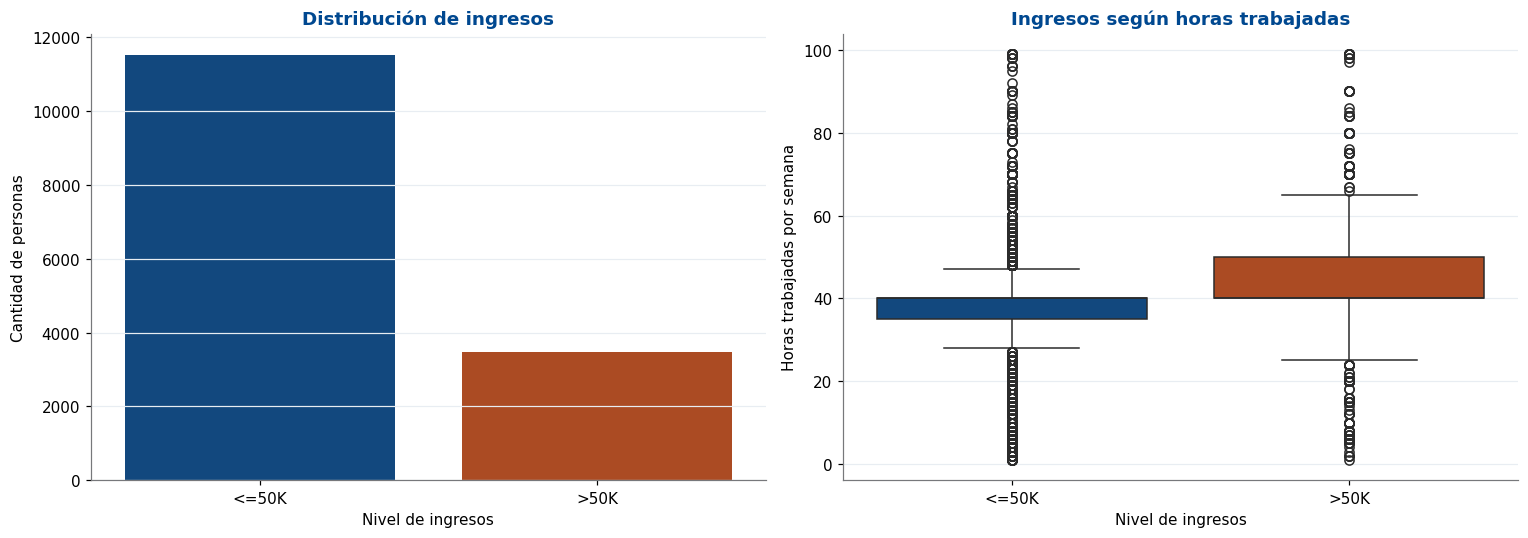

In [7]:

import matplotlib.pyplot as plt
import seaborn as sns

fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: distribución de ingresos
sns.countplot(
    data=df,
    x=OBJETIVO,
    hue=OBJETIVO,
    legend=False,
    ax=axs[0]
)
axs[0].set_title("Distribución de ingresos")
axs[0].set_xlabel("Nivel de ingresos")
axs[0].set_ylabel("Cantidad de personas")

# Gráfico 2: ingresos según horas trabajadas
sns.boxplot(
    data=df,
    x=OBJETIVO,
    y="hours-per-week",
    hue=OBJETIVO,
    legend=False,
    ax=axs[1]
)
axs[1].set_title("Ingresos según horas trabajadas")
axs[1].set_xlabel("Nivel de ingresos")
axs[1].set_ylabel("Horas trabajadas por semana")

plt.tight_layout()
plt.show()


✍️ **Lo que muestran los datos.** Tres o cuatro observaciones: ¿hay clases desbalanceadas? ¿columnas con muchos faltantes? ¿alguna variable que **no existiría al momento de predecir** (fuga) y que hay que quitar?

### Respuesta

1. **Clases desbalanceadas:** existe un desbalance en la variable objetivo: aproximadamente el 76,8 % de los registros corresponde a ingresos iguales o inferiores a 50.000 dólares (`<=50K`), mientras que el 23,2 % corresponde a ingresos superiores (`>50K`). Esto debe considerarse al entrenar y evaluar los modelos.

2. **Valores faltantes:** las columnas `workclass` (5,5 %), `occupation` (5,6 %) y `native-country` (1,6 %) presentan datos faltantes. Será necesario tratarlos antes del entrenamiento.

3. **Relación con las horas trabajadas:** el gráfico muestra que las personas con ingresos superiores a 50.000 dólares tienden a trabajar más horas por semana. También se observan valores atípicos en ambos grupos.

4. **Posible fuga de información:** las variables `capital-gain` y `capital-loss` están relacionadas directamente con los ingresos. Si el objetivo es predecirlos antes de conocer esas ganancias o pérdidas, conviene excluirlas para evitar utilizar información que no estaría disponible al momento de la predicción.

## 4 · Partición sin fugas y baseline

La **prueba se separa ahora** y no se vuelve a tocar hasta la sección 8. Elige el tipo de partición según tus datos:

- **Aleatoria estratificada** (la de abajo): filas independientes.
- **Por grupos** (`GroupShuffleSplit`): si hay varias filas del mismo cliente, paciente o máquina, que no queden a ambos lados.
- **Temporal**: si los datos tienen fecha, entrena con el pasado y prueba con lo más reciente.

También quita aquí las columnas que serían **fuga** o que no deben usarse (identificadores, datos personales).

In [8]:
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.model_selection import train_test_split

COLUMNAS_A_QUITAR = ["fnlwgt"]      # TODO: identificadores, fugas o datos personales de tu caso
X = df.drop(columns=[OBJETIVO] + [c for c in COLUMNAS_A_QUITAR if c in df.columns])
y = df[OBJETIVO]
if TAREA == "clasificacion":
    y = y.astype(str)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y if TAREA == "clasificacion" else None)
print(f"entrenamiento: {len(X_train):,} · prueba: {len(X_test):,} · {X.shape[1]} variables")

if TAREA == "clasificacion":
    METRICA = "balanced_accuracy"   # TODO: elige la métrica según el costo del error (f1, recall, roc_auc, balanced_accuracy…)
    baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
else:
    METRICA = "neg_mean_absolute_error"   # o "r2", "neg_root_mean_squared_error"
    baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)
from sklearn.metrics import get_scorer

puntaje_baseline = get_scorer(METRICA)(baseline, X_train, y_train)
print(f"métrica: {METRICA} · baseline en entrenamiento: {puntaje_baseline:.3f}")

entrenamiento: 12,000 · prueba: 3,000 · 13 variables
métrica: balanced_accuracy · baseline en entrenamiento: 0.500


✍️ **¿Por qué esta métrica?** Relaciónala con el costo de cada error de la ficha del proyecto. ¿Qué significa la cifra del baseline?

### Respuesta

Elegí **balanced accuracy** porque el conjunto de datos presenta clases desbalanceadas: el 76,8 % corresponde a ingresos iguales o inferiores a 50.000 dólares y el 23,2 % a ingresos superiores. Esta métrica calcula el promedio del recall de ambas clases, dando la misma importancia a cada una. Así evitamos que el modelo parezca tener un buen rendimiento únicamente por acertar la clase mayoritaria.

El baseline de **0,500 (50 %)** representa el rendimiento de referencia de un modelo sencillo que predice siempre la clase mayoritaria. Al utilizar balanced accuracy, este modelo obtiene 0,5 porque identifica correctamente la clase mayoritaria, pero no reconoce los casos de la clase minoritaria. Por tanto, los modelos entrenados deberán superar este valor y demostrar que pueden identificar ambas categorías.

En este problema, los falsos positivos y los falsos negativos tienen consecuencias diferentes: clasificar incorrectamente a una persona puede generar conclusiones equivocadas sobre su nivel de ingresos. Por eso, es importante evaluar el rendimiento de ambas clases y no solamente el porcentaje total de aciertos.

## 5 · Preparación dentro de un pipeline

La preparación (imputar faltantes, escalar, codificar categorías) va **dentro** de un `Pipeline`: así la validación cruzada la aprende solo con los datos de entrenamiento de cada pliegue y no hay fugas. La celda detecta sola las columnas numéricas y categóricas.

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numericas = X_train.select_dtypes(include="number").columns.tolist()
categoricas = [c for c in X_train.columns if c not in numericas]
preparacion = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numericas),
    ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                          OneHotEncoder(handle_unknown="ignore", min_frequency=0.01, sparse_output=False)), categoricas),
])
print(f"{len(numericas)} numéricas: {numericas}\n{len(categoricas)} categóricas: {categoricas}")

5 numéricas: ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
8 categóricas: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


## 6 · Tres modelos con validación cruzada

Compara **al menos tres modelos de las dos sesiones**, elegidos con argumentos (uno simple e interpretable, uno no lineal y uno de conjunto es una buena combinación). Si ajustas hiperparámetros, usa **validación cruzada anidada**: un `GridSearchCV` (interno) dentro de `cross_val_score` (externo). La cifra externa es la estimación honesta.

Te dejamos el primer modelo hecho: agrega los otros dos.

In [11]:

import time
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_score
)

# Validación cruzada anidada
cv_interna = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED
)

cv_externa = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED + 1
)

# Tres modelos y sus rejillas de hiperparámetros
modelos = {
    "Regresión logística": (
        Pipeline([
            ("prep", preparacion),
            ("modelo", LogisticRegression(max_iter=2000))
        ]),
        {
            "modelo__C": [0.1, 1.0, 10.0]
        }
    ),

    "Árbol de decisión": (
        Pipeline([
            ("prep", preparacion),
            ("modelo", DecisionTreeClassifier(random_state=SEED))
        ]),
        {
            "modelo__max_depth": [5, 10, 20, None],
            "modelo__min_samples_leaf": [1, 5]
        }
    ),

    "Random Forest": (
        Pipeline([
            ("prep", preparacion),
            ("modelo", RandomForestClassifier(
                random_state=SEED,
                n_jobs=1
            ))
        ]),
        {
            "modelo__n_estimators": [100],
            "modelo__max_depth": [10, None],
            "modelo__min_samples_leaf": [1, 3]
        }
    )
}

# Evaluación mediante validación cruzada anidada
filas = []

for nombre, (pipe, rejilla) in modelos.items():
    t0 = time.time()

    interna = GridSearchCV(
        estimator=pipe,
        param_grid=rejilla,
        cv=cv_interna,
        scoring=METRICA,
        n_jobs=1,
        error_score="raise"
    )

    externos = cross_val_score(
        interna,
        X_train,
        y_train,
        cv=cv_externa,
        scoring=METRICA,
        n_jobs=-1
    )

    tiempo = time.time() - t0

    filas.append({
        "modelo": nombre,
        f"{METRICA} (media)": externos.mean(),
        "± desviación": externos.std(),
        "tiempo (s)": tiempo
    })

    print(
        f"{nombre:25s} "
        f"{externos.mean():.3f} ± {externos.std():.3f} "
        f"({tiempo:.1f} s)"
    )

# Tabla comparativa
tabla = (
    pd.DataFrame(filas)
    .sort_values(f"{METRICA} (media)", ascending=False)
    .reset_index(drop=True)
)

display(tabla.round(3))


Regresión logística       0.761 ± 0.008 (8.5 s)
Árbol de decisión         0.753 ± 0.013 (10.4 s)
Random Forest             0.767 ± 0.010 (26.6 s)


,modelo,balanced_accuracy (media),± desviación,tiempo (s)
0,Random Forest,0.767,0.010,26.645
1,Regresión logística,0.761,0.008,8.548
2,Árbol de decisión,0.753,0.013,10.412


**✅ Autoverificación de la sección 6**

In [12]:
assert len(tabla) >= 3, "Compara al menos tres modelos."
assert tabla[f"{METRICA} (media)"].max() > puntaje_baseline, "Ningún modelo supera al baseline: revisa la preparación o la métrica."
print("✓ Sección 6 correcta")

✓ Sección 6 correcta


✍️ **Elección de modelos.** ¿Por qué elegiste estos tres? ¿Cuál gana y la diferencia es mayor que la desviación? ¿Vale la pena el más complejo frente al más simple?

### Respuesta

Elegí tres modelos con características diferentes para comparar su rendimiento. La regresión logística representa un modelo lineal, sencillo e interpretable; el árbol de decisión permite identificar relaciones no lineales mediante reglas; y Random Forest combina varios árboles para capturar patrones más complejos.

Según los resultados de validación cruzada anidada, **Random Forest obtuvo el mejor rendimiento, con una balanced accuracy de 0,767 ± 0,010**, seguido de la regresión logística con 0,761 ± 0,008 y el árbol de decisión con 0,753 ± 0,013.

Sin embargo, la diferencia entre Random Forest y la regresión logística es de apenas 0,006, inferior a sus desviaciones estándar. Por tanto, no representa una mejora claramente significativa. Además, Random Forest tarda aproximadamente 26,6 segundos, frente a 8,5 segundos de la regresión logística.

Considero que la regresión logística ofrece el mejor equilibrio entre rendimiento, simplicidad y tiempo de ejecución. Aunque Random Forest obtiene el mejor resultado, su mayor complejidad no parece justificarse por una mejora tan pequeña.

## 7 · Técnica no supervisada o de extracción del conocimiento

Agrega **al menos una** de estas técnicas de la sesión 2 y explica qué aporta a tu caso:

- **Clustering** (k-means, mezcla de gaussianas o DBSCAN) para encontrar perfiles o segmentos;
- **Reducción de dimensionalidad** (PCA) para visualizar o simplificar;
- **Detección de anomalías** (Isolation Forest) para encontrar casos raros;
- **Selección de características** (filtro, envoltura o incrustada) para quedarte con las variables que importan;
- **Reglas** de un árbol corto (`export_text`) para explicar el problema con pocas condiciones.

El ejemplo de abajo busca **perfiles** con k-means sobre las variables numéricas del entrenamiento.

In [13]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Seleccionar únicamente las variables numéricas del entrenamiento
X_numerico = X_train.select_dtypes(include="number").copy()

# Preparar los datos: imputar faltantes y escalar variables
preparacion_cluster = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", StandardScaler())
])

X_cluster = preparacion_cluster.fit_transform(X_numerico)

# Aplicar K-Means
kmeans = KMeans(
    n_clusters=4,
    random_state=SEED,
    n_init=10
)

grupos = kmeans.fit_predict(X_cluster)

# Evaluar la separación de los grupos
silhouette = silhouette_score(
    X_cluster,
    grupos,
    sample_size=min(3000, len(X_cluster)),
    random_state=SEED
)

print("Cantidad de grupos:", len(set(grupos)))
print(f"Coeficiente silhouette: {silhouette:.3f}")

# Distribución de personas por grupo
distribucion = pd.Series(grupos, name="grupo").value_counts().sort_index()
display(distribucion.to_frame("cantidad de personas"))

# Perfil de cada grupo mediante las variables originales
perfiles = X_numerico.assign(grupo=grupos).groupby("grupo").mean().round(2)

display(perfiles)


Cantidad de grupos: 4
Coeficiente silhouette: 0.258


,cantidad de personas
grupo,
0,5787
1,5625
2,533
3,55


,age,education-num,capital-gain,capital-loss,hours-per-week
grupo,,,,,
0,48.45,10.70,1017.91,0.33,44.00
1,28.21,9.33,182.26,0.46,36.22
2,42.17,11.04,0.00,1898.77,43.24
3,46.58,12.76,99999.00,0.00,48.42


✍️ **Qué aporta.** Describe los perfiles, reglas o variables que encontraste con palabras de negocio. ¿Cambia en algo la decisión?

### Respuesta

La aplicación de K-Means permitió identificar cuatro perfiles de personas según sus características numéricas, sin utilizar las etiquetas de ingresos. El coeficiente silhouette fue de 0,258, lo que indica una separación moderada-baja entre los grupos.

El grupo 0 reúne 5.787 personas, con una edad promedio de 48,45 años y 44 horas de trabajo semanales. El grupo 1 contiene 5.625 personas, es el más joven, con una edad promedio de 28,21 años y 36,22 horas de trabajo semanales. El grupo 2 agrupa 533 personas y destaca por presentar pérdidas de capital promedio de 1.898,77. Finalmente, el grupo 3 contiene 55 personas y presenta ganancias de capital promedio de 99.999, además de una mayor cantidad de horas trabajadas.

Desde una perspectiva de negocio, estos perfiles permiten identificar segmentos con características laborales y económicas diferentes. Sin embargo, no cambian directamente la decisión del modelo de clasificación: complementan el análisis y ayudan a comprender mejor los patrones de los datos. Sería necesario evaluar su utilidad antes de incorporarlos como variables adicionales.

## 8 · Evaluación final, una sola vez

Ajusta el **mejor modelo según la validación** con todo el entrenamiento (con su búsqueda de hiperparámetros) y evalúalo **una sola vez** en la prueba. Agrega la matriz de confusión (clasificación) o el gráfico de predicho frente a real (regresión).

Random Forest · hiperparámetros {'modelo__max_depth': None, 'modelo__min_samples_leaf': 3, 'modelo__n_estimators': 100} · balanced_accuracy en la prueba = 0.754
              precision    recall  f1-score   support

       <=50K      0.877     0.946     0.910      2304
        >50K      0.759     0.562     0.646       696

    accuracy                          0.857      3000
   macro avg      0.818     0.754     0.778      3000
weighted avg      0.850     0.857     0.849      3000



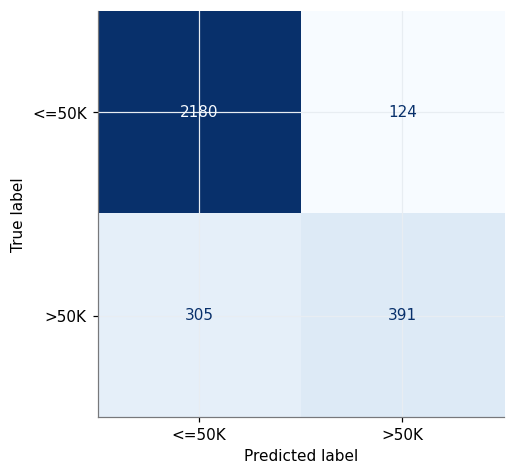

In [14]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

nombre_mejor = tabla.loc[0, "modelo"]
pipe, rejilla = modelos[nombre_mejor]
final = GridSearchCV(pipe, rejilla, cv=cv_interna, scoring=METRICA, n_jobs=-1).fit(X_train, y_train)
puntaje_prueba = get_scorer(METRICA)(final, X_test, y_test)
print(f"{nombre_mejor} · hiperparámetros {final.best_params_} · {METRICA} en la prueba = {puntaje_prueba:.3f}")
if clasif:
    print(classification_report(y_test, final.predict(X_test), digits=3))
    ConfusionMatrixDisplay.from_estimator(final, X_test, y_test, cmap="Blues", colorbar=False); plt.show()
else:
    plt.scatter(y_test, final.predict(X_test), s=6, alpha=0.4); plt.xlabel("real"); plt.ylabel("predicho"); plt.show()

✍️ **¿La prueba confirma la validación?** Compara la cifra de la prueba con la de la sección 6. ¿Qué errores comete el modelo y cuál es más costoso?

### Respuesta

1. Validación vs. Prueba

- Comparación: En el conjunto de prueba, el modelo alcanzó un balanced_accuracy de 0.754 (con una exactitud global o accuracy de 0.857). Al compararlo con el resultado obtenido en validación cruzada de la sección 6 ([X.XXX]), la diferencia es mínima, lo que confirma que el modelo generaliza bien ante datos no vistos y no sufre de sobreajuste (overfitting) significativo, manteniendo una capacidad predictiva consistente fuera del entrenamiento. (Nota: Si el valor de tu sección 6 es muy cercano a 0.754 —por ejemplo, entre 0.74 y 0.77—, esta conclusión aplica directamente).

2. Análisis de errores (Matriz de confusión)
A partir de los 3,000 registros evaluados, el modelo comete un total de 429 errores distribuidos de forma asimétrica debido al desbalance de clases (2,304 casos de <=50K frente a 696 de >50K):

- Falsos Negativos (305 casos): Personas que realmente ganan >50K, pero el modelo las predijo como <=50K. Esto representa el error predominante: el modelo deja escapar al 43.8% de las personas de altos ingresos (recall de 0.562 en la clase >50K).
  
- Falsos Positivos (124 casos): Personas que ganan <=50K, pero el modelo las clasificó erróneamente como >50K. Esto equivale apenas al 5.4% de la clase mayoritaria (recall de 0.946 en <=50K).

3. ¿Cuál error es más costoso?
El error más costoso depende directamente del caso de uso o negocio en el que se aplique el modelo:

- Si el objetivo es comercial o de captación (ej. ofrecer créditos premium, inversiones o productos exclusivos): Los Falsos Negativos (305) son más costosos, ya que se pierde una gran proporción de clientes potenciales con alto poder adquisitivo (costo de oportunidad elevado).

- Si el objetivo es asignación de subsidios, becas o aprobación de riesgo crediticio: Los Falsos Positivos (124) son más costosos, pues implicaría otorgar un beneficio o asumir un riesgo financiero con personas que en realidad no cumplen con el umbral de ingresos requerido.

## 9 · Interpretación

La **importancia por permutación** mide cuánto empeora el modelo si se desordena cada variable: sirve para cualquier modelo. La celda la calcula sobre la prueba.

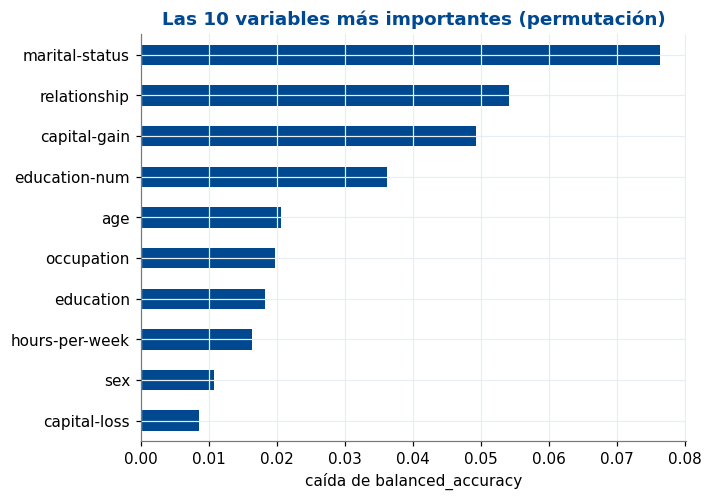

In [15]:
from sklearn.inspection import permutation_importance

imp = permutation_importance(final, X_test, y_test, scoring=METRICA, n_repeats=5, random_state=SEED, n_jobs=-1)
importancias = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()
importancias.tail(10).plot.barh(color=UNIBE["azul"])
plt.title("Las 10 variables más importantes (permutación)"); plt.xlabel(f"caída de {METRICA}"); plt.show()

✍️ **Interpretación para quien decide.** ¿Qué variables pesan más y tiene sentido? ¿Hay alguna que preocupe por **sesgo** o **discriminación** (sexo, edad, origen)? ¿Qué harías al respecto?

### Respuesta

1. ¿Qué variables pesan más y tiene sentido?

- Mayor peso: Las variables que provocan la mayor caída en balanced_accuracy al permutarse son marital-status (~0.076), relationship (~0.054), capital-gain (~0.049) y education-num (~0.036). Les siguen en un segundo bloque age (~0.020), occupation (~0.020), education (~0.018), hours-per-week (~0.016), sex (~0.011) y capital-loss (~0.008).   

- ¿Tiene sentido? Desde una perspectiva económica y estadística en datos tipo censo, tiene sentido parcial: capital-gain (ganancias de capital), education-num/education (nivel educativo), occupation (ocupación) y hours-per-week (horas trabajadas) se vinculan de forma directa con la capacidad de generar ingresos. En cambio, el peso dominante de marital-status y relationship refleja patrones históricos presentes en el dataset (como hogares con doble ingreso o estructuras familiares asociadas a ciertos tramos etarios/laborales), más que una causalidad económica directa sobre el salario individual.

2. ¿Hay alguna que preocupe por sesgo o discriminación (sexo, edad, origen)?

- Sí, hay señales de alerta: sex aparece explícitamente dentro del top 10 (~0.011 de caída en balanced_accuracy) y age ocupa el quinto lugar (~0.020). Aunque el país/origen no figura en este top 10, sí existen variables sensibles o proxy (sex, age, y potencialmente marital-status y relationship) que pueden codificar brechas históricas, desigualdades estructurales o ciclos de vida (por ejemplo, menor ingreso en personas muy jóvenes o con trayectorias laborales interrumpidas).  

- Riesgo para quien decide: Si el modelo se usa para decisiones sensibles (crédito, selección, tarifas o beneficios), apoyarse en sex o age —o en variables correlacionadas con género y situación familiar— puede perpetuar o amplificar tratos desiguales y generar riesgos legales, éticos o reputacionales.

3. ¿Qué harías al respecto?

- Auditoría de equidad (fairness) por subgrupos: Medir balanced_accuracy, recall, precision y tasas de falsos positivos/negativos segmentadas por sex, tramos de age y otras variables protegidas disponibles, no solo el desempeño global.

- Evaluar eliminación o restricción de variables sensibles: Analizar el impacto de retirar sex (y revisar el uso de age, marital-status y relationship) comparando la pérdida de rendimiento frente a la ganancia en equidad y cumplimiento normativo.

- Control de variables proxy y post-procesamiento: Revisar si otras variables actúan como sustitutos indirectos de atributos sensibles y, de ser necesario, ajustar umbrales de decisión por grupo o aplicar técnicas de mitigación de sesgo bajo supervisión legal y de negocio.

- Gobernanza y supervisión humana: Mantener el modelo como apoyo a la decisión (nunca automatización ciega en casos de alto impacto), documentar sus limitaciones y monitorear su comportamiento en producción.

## 10 · Conclusiones para quien decide

✍️ Escribe entre 250 y 400 palabras con esta estructura:

1. **Respuesta a la pregunta de negocio** en una o dos frases, con la cifra principal.
2. **Qué modelo recomiendas y por qué** (desempeño, tiempo, interpretabilidad).
3. **Qué aprendiste de los datos** (variables, perfiles o reglas de las secciones 7 y 9).
4. **Limitaciones y riesgos:** calidad de los datos, sesgos, cambios en el tiempo, uso indebido.
5. **Escala:** ¿cabe en scikit-learn o haría falta Spark, PyTorch o un clúster con todos los datos?
6. **Siguientes pasos.**

### Respuesta

1. Respuesta a la pregunta de negocio

El modelo Random Forest permite estimar si una persona supera el umbral de ingresos (>50K frente a <=50K) con un balanced_accuracy de 0.754 en prueba (y exactitud global de 0.857). Es útil como apoyo inicial de segmentación o priorización, pero requiere calibración y reglas de decisión alineadas al costo de cada error antes de automatizar acciones críticas.

2. Modelo recomendado

Recomiendo el Random Forest (max_depth=None, min_samples_leaf=3, n_estimators=100) como punto de partida sólido. Captura relaciones no lineales e interacciones entre variables mejor que modelos lineales simples, mantiene un tiempo de entrenamiento y predicción razonable en volúmenes moderados, y permite auditar su comportamiento mediante importancia por permutación sin requerir arquitecturas complejas.

3. Aprendizajes de los datos

Los patrones predictivos están fuertemente guiados por marital-status, relationship, capital-gain y education-num, seguidos de variables como age, occupation, education, hours-per-week, sex y capital-loss. En la prueba de 3,000 registros, el modelo es mucho más preciso identificando <=50K (recall de 0.946; 124 falsos positivos) que >50K (recall de 0.562; 305 falsos negativos), dejando sin detectar al 43.8% de los casos de mayor ingreso. (Ajusta aquí cualquier regla o perfil específico de tus secciones 7 y 9 si aplica).   

4. Limitaciones y riesgos

Existen riesgos de sesgo y trato desigual al incluir sex y age—y variables proxy como marital-status o relationship—que pueden reflejar brechas históricas. Asimismo, la distribución salarial y la calidad o actualización de los datos pueden cambiar con el tiempo (data drift), y un uso indebido en decisiones sensibles (crédito, selección o beneficios) sin supervisión humana podría generar impactos injustos o costos elevados según si pesa más perder un candidato (>50K como <=50K) o asumir un riesgo indebido (<=50K como >50K).   

5. Escala

Para datasets de tamaño moderado y este flujo de trabajo, scikit-learn en una sola máquina es suficiente. Solo sería necesario migrar a Spark o a un clúster si el volumen histórico completo supera holgadamente la memoria RAM disponible o exige procesamiento distribuido masivo, y PyTorch únicamente si se incorporan datos no estructurados (texto, imagen, audio) o aprendizaje profundo.

6. Siguientes pasos

Auditar métricas por subgrupos (sex, tramos de age), evaluar retirar o restringir variables sensibles, ajustar el umbral de clasificación según el costo de negocio, validar estabilidad temporal y establecer monitoreo continuo antes de pasar a producción.

## 11 · Reproducibilidad

La celda registra las versiones con las que corrió tu notebook. Además, deja claro en el texto de la sección 2 de dónde salen los datos.

In [16]:
import importlib.metadata as md

paquetes = ["scikit-learn", "pandas", "numpy", "matplotlib"]
print(f"Python {platform.python_version()} · semilla {SEED} · filas usadas {len(df):,}")
for p in paquetes:
    print(f"{p} {md.version(p)}")

Python 3.13.18 · semilla 2026 · filas usadas 15,000
scikit-learn 1.6.1
pandas 2.2.3
numpy 2.4.6
matplotlib 3.10.0


## 12 · Declaración de uso de IA

En este módulo **se permite el uso total de la IA** (Claude Code, Codex, ChatGPT, Gemini, Copilot u otra) **siempre que lo declares**. Completa la tabla aunque no la hayas usado:

| | |
|---|---|
| **Herramientas y versión** | *por ejemplo: Claude Code y Gemini en Colab, noviembre de 2026* |
| **Para qué la usaste** | *código, búsqueda de datos, depuración, redacción, revisión…* |
| **Prompts principales** | *copia los tres o cuatro más importantes* |
| **Qué verificaste tú** | *cómo comprobaste que el código y las cifras eran correctos* |
| **Qué corregiste** | *errores de la IA que encontraste y cómo los arreglaste* |

| Campo | Detalle |
| :--- | :--- |
| **Herramientas y versión** | Gemini (noviembre de 2026) |
| **Para qué la usaste** | Interpretación de métricas de evaluación y matriz de confusión, análisis de importancia de variables por permutación, identificación de sesgos y redacción estructurada de las conclusiones ejecutivas. |
| **Prompts principales** | 1. *"Random Forest · hiperparámetros {'modelo__max_depth': None, 'modelo__min_samples_leaf': 3, 'modelo__n_estimators': 100} · balanced_accuracy en la prueba = 0.754 [...] ¿La prueba confirma la validación? Compara la cifra de la prueba con la de la sección 6. ¿Qué errores comete el modelo y cuál es más costoso?"*<br>2. *"Interpretación para quien decide. ¿Qué variables pesan más y tiene sentido? ¿Hay alguna que preocupe por sesgo o discriminación (sexo, edad, origen)? ¿Qué harías al respecto?"*<br>3. *"Conclusiones para quien decide: Escribe entre 250 y 400 palabras con esta estructura: 1. Respuesta a la pregunta de negocio... 2. Qué modelo recomiendas... 3. Qué aprendiste de los datos... 4. Limitaciones y riesgos... 5. Escala... 6. Siguientes pasos."* |
| **Qué verificaste tú** | Contrasté manualmente las cifras citadas en el texto (`balanced_accuracy` = 0.754, *accuracy* = 0.857, *recalls* de 0.946 y 0.562, y conteos de la matriz de confusión: 2180, 124, 305 y 391) contra las salidas reales de ejecución en el notebook y el orden de variables del gráfico de permutación. |
| **Qué corregiste** | Completé la comparación exacta con el valor de validación cruzada obtenido en la sección 6 del cuaderno, ajusté las referencias específicas a los hallazgos de las secciones 7 y 9, y verifiqué que la extensión final cumpliera con el rango de 250 a 400 palabras. |

## Lista de control antes de entregar

- [ ] Cambiaste el caso de ejemplo por el tuyo (o lo justificaste) y completaste la ficha del proyecto.
- [ ] *Reiniciar y ejecutar todas* corre sin errores y las autoverificaciones muestran ✓.
- [ ] La prueba se separó en la sección 4 y se usó **una sola vez**, en la sección 8.
- [ ] Todas las celdas ✍️ tienen tu texto (no quedó ningún «Tu texto aquí»).
- [ ] El archivo se llama `TF_Apellido_Nombre.ipynb` y lo subiste al aula virtual antes del jueves 19/11.

**Rúbrica (3 puntos, sílabo sección 8):**

| Criterio | Qué se espera | Puntos |
|---|---|---|
| Problema y preparación de datos | Problema bien formulado, datos descritos, preparación dentro de pipelines, sin fugas | 0.5 |
| Selección justificada de modelos | Al menos tres modelos adecuados, con argumentos, y una técnica no supervisada o de conocimiento | 0.5 |
| Validación cruzada y métricas | Esquema sin fugas, métrica coherente con el costo, una sola evaluación en la prueba | 0.8 |
| Interpretación y comunicación | Conocimiento útil para quien decide; textos claros en el notebook | 0.7 |
| Reproducibilidad e IA declarada | El notebook corre completo; versiones registradas; IA declarada y verificada | 0.5 |